# HomeWork -4
## Objective
 In this homework, you will design a python class that encapsulates common univariate/bivariate analysis tasks. You will practice object oriented programing (OOP) while applying descriptive statistics and visualization to summarize your data and explore the relationship between two variables.

 - Use the example provided in the class activity and expand it. The initializer of the class should take data and print out its shape and column names.
 - Additionally, your class should include at least 5 methods (function) to do either univariate or bivariate analysis of your choice.
 - Provide markdowns or comments for each part of your code.  

  - Create an instance of your class using Penguin data and use it to analyze it.
  
  - For each analysis you perform, write 1-2 sentence before that function call that clearly state
    the question you are trying to answer with that analysis. For example: "In this analysis I want to see what is the average mass for each species."

  


## 1. Create the Analysis Class
I created a class called `DataAnalyzer` to keep the analysis methods in one place. The initializer stores the dataset and prints its shape and column names. The five methods let me summarize numeric columns, count categories, plot a distribution, compare group averages, and graph two variables.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Create a class with five analysis methods.

class DataAnalyzer:
    """
    A class for summarizing data and making graphs.
    """
    def __init__(self, data: pd.DataFrame):
        """
        Store the dataset and print its shape and column names.
        """
        if not isinstance(data, pd.DataFrame):
            raise ValueError("Input data must be a pandas DataFrame.")
        self.data = data
        print("--- DataAnalyzer Initialized ---")
        print(f"Shape of dataset: {self.data.shape[0]} rows, {self.data.shape[1]} columns")
        print(f"Columns in dataset: {list(self.data.columns)}")
        print("--------------------------------")

    # Method 1: Summarize numeric columns.
    def get_summary_statistics(self, columns=None):
        """
        Return summary statistics for the selected numeric columns.
        """
        target_cols = columns if columns else self.data.select_dtypes(include='number').columns
        return self.data[target_cols].describe()

    # Method 2: Count and graph categories.
    def analyze_categorical(self, column: str):
        """
        Show counts, percentages, and a bar chart for a category.
        """
        counts = self.data[column].value_counts(dropna=False)
        pcts = self.data[column].value_counts(normalize=True, dropna=False) * 100
        summary_df = pd.DataFrame({'Counts': counts, 'Percentage (%)': pcts})
        print(f"Distribution of '{column}':\n", summary_df)

        plt.figure(figsize=(6, 4))
        sns.countplot(data=self.data, x=column, hue=column, palette='Set2', legend=False)
        plt.title(f'Distribution of {column}')
        plt.show()

    # Method 3: Graph a numeric distribution.
    def plot_distribution(self, column: str):
        """
        Make a histogram with a smooth curve for a numeric column.
        """
        plt.figure(figsize=(6, 4))
        sns.histplot(data=self.data, x=column, kde=True, color='skyblue')
        plt.title(f'Distribution of {column}')
        plt.show()

    # Method 4: Compare numeric summaries by group.
    def aggregate_by_category(self, numeric_col: str, group_col: str):
        """
        Find the mean, median, and standard deviation for each group.
        """
        return self.data.groupby(group_col)[numeric_col].agg(['mean', 'median', 'std'])

    # Method 5: Graph the relationship between two variables.
    def plot_bivariate_relationship(self, x_col: str, y_col: str, hue_col: str = None):
        """
        Compare two variables with a scatterplot or boxplot.
        """
        plt.figure(figsize=(8, 5))
        if pd.api.types.is_numeric_dtype(self.data[x_col]):
            sns.scatterplot(data=self.data, x=x_col, y=y_col, hue=hue_col, palette='Set1')
            plt.title(f'Relationship between {x_col} and {y_col}')
        else:
            sns.boxplot(data=self.data, x=x_col, y=y_col, hue=hue_col, palette='Set2')
            plt.title(f'{y_col} Distribution by {x_col}')
        plt.show()

## 2. Load the Penguin Data
I loaded the penguins dataset and removed rows with missing values before creating an instance of the class. The analyses below use the remaining complete rows, so the results describe that smaller dataset.

In [ ]:
# Load the data and keep rows with no missing values.
penguins = sns.load_dataset("penguins").dropna()

# Create an instance of the class.
analyzer = DataAnalyzer(penguins)

--- DataAnalyzer Initialized ---
Shape of dataset: 333 rows, 7 columns
Columns in dataset: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']
--------------------------------



## 3. Summary Statistics
In this analysis, I want to see the average bill length, bill depth, flipper length, and body mass of the penguins. I also want to see how much these measurements vary.

In [ ]:
print(analyzer.get_summary_statistics(['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']))

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count      333.000000     333.000000         333.000000   333.000000
mean        43.992793      17.164865         200.966967  4207.057057
std          5.468668       1.969235          14.015765   805.215802
min         32.100000      13.100000         172.000000  2700.000000
25%         39.500000      15.600000         190.000000  3550.000000
50%         44.500000      17.300000         197.000000  4050.000000
75%         48.600000      18.700000         213.000000  4775.000000
max         59.600000      21.500000         231.000000  6300.000000



The cleaned dataset contains **333 penguins**. Their average body mass was about **4,207 grams**, and their average flipper length was about **201 mm**. Body mass ranged from **2,700 to 6,300 grams**, showing a noticeable difference in size across the penguins.

## 4. Species Counts
In this analysis, I want to see how many penguins belong to each species and which species makes up the largest part of the cleaned dataset.

Distribution of 'species':
            Counts  Percentage (%)
species                          
Adelie        146       43.843844
Gentoo        119       35.735736
Chinstrap      68       20.420420


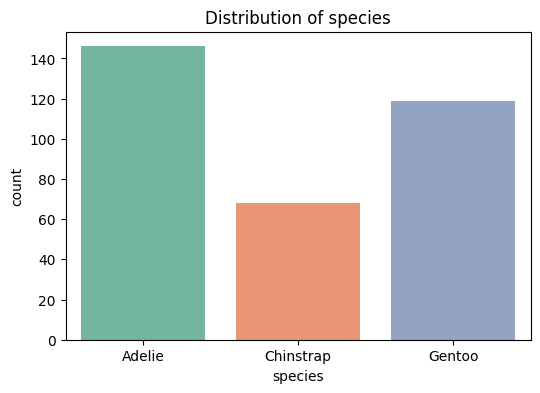

In [ ]:
analyzer.analyze_categorical('species')

Adelie was the largest group with **146 penguins**, followed by Gentoo with **119** and Chinstrap with **68**. They made up about **43.8%**, **35.7%**, and **20.4%** of the cleaned dataset, respectively.

## 5. Body Mass Distribution
In this analysis, I want to see how the penguins' body masses are distributed. The histogram helps me look for common weight ranges and whether the distribution has more than one peak.

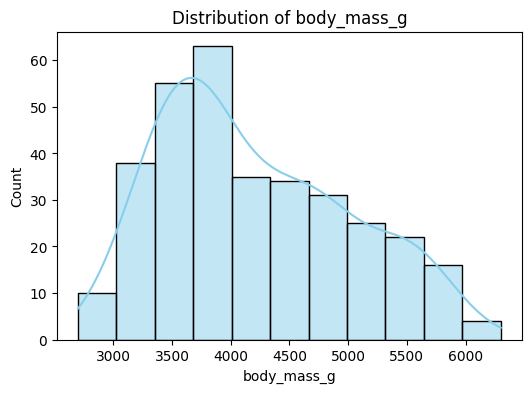

In [ ]:
analyzer.plot_distribution('body_mass_g')

## 6. Body Mass by Species
In this analysis, I want to see which species has the highest average body mass. I also want to compare how much body mass varies within each species.

In [ ]:
print(analyzer.aggregate_by_category('body_mass_g', 'species'))

                  mean  median         std
species                                   
Adelie     3706.164384  3700.0  458.620135
Chinstrap  3733.088235  3700.0  384.335081
Gentoo     5092.436975  5050.0  501.476154



Gentoo penguins had the highest average body mass at about **5,092 grams**. Adelie and Chinstrap had similar averages of about **3,706** and **3,733 grams**. Gentoo also had the largest standard deviation, meaning its body masses varied the most among the three groups.

## 7. Bill Length and Bill Depth
In this analysis, I want to see how bill length and bill depth relate to each other and whether the pattern differs by species. I used a different color for each species to make the groups easier to compare.

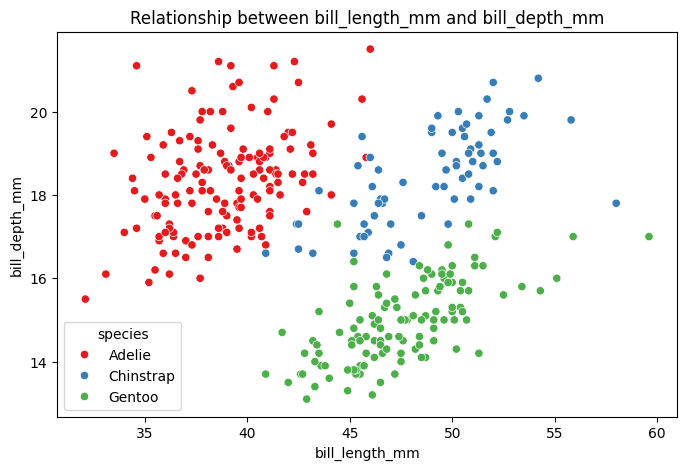

In [ ]:
analyzer.plot_bivariate_relationship(x_col='bill_length_mm', y_col='bill_depth_mm', hue_col='species')